# 073 — Statistical models for the fragility comparison (legacy: `AvgSA_03__ks` vs FEMA P695)

> **Legacy notebook — side quest.** A copy of main-line nb `073`, pinned to the study
> `AvgSA_03__ks__vs__femap695`: the *original* site-specific record sets (weak SSE + KS-acceptance
> selection) against the FEMA P695 fixed set. It is kept to show the results that led to
> optimising the record selection (see this folder's `README.md` and nb `034`). It does not
> read `record_sets.active_study`, so changing the main line never changes what it does.
> Every model referenced in the sections below is fitted when the notebook is run.

Fits the A-series models to the dataset nb `072` writes for the pinned study (`AvgSA_03__ks__vs__femap695`).

Everything here runs on `phd_project/scripts/fragility_data_models.py`, which owns the loading,
the crossed factors, the sampling covariance and the model registry. Notebook `076_refactor`
documents that data model and is the place to look for *how it works*; this notebook is for the
results.

**The three arms** (CLAUDE.md §2), all on the log scale:

| symbol | arm | varies with | record set |
|---|---|---|---|
| $a_i$ | MSA site-specific | site & structure | selected per stripe, per site, by GCIM |
| $b_j$ | MSA fixed set | design only | one fixed FEMA P695 set, shared |
| $c_j$ | IDA fixed set | design only | the same fixed set |

**The contrasts.** $y^{(0)}_i = a_i - c_{g[i]}$ (120 rows), $y^{(1)}_i = a_i - b_{g[i]}$
(120 rows), $y^{(2)}_j = b_j - c_j$ (51 rows). The identity
$y^{(0)}_i \equiv y^{(1)}_i + y^{(2)}_{g[i]}$ holds exactly at row level — but see §3.0 for why
the *fitted summaries* do not simply add.

**Models fitted here:** A0a, A1a and A2, each by DerSimonian–Laird and by REML, plus §2.4's
collapse-bracket variants. A1b and A1c — the three-level and crossed design × site fits_theta, which
are the reportable A1 rungs — are **not** fitted yet.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from phd_project.scripts import fixed_record_sets as fxr
import phd_project.scripts.metaregression_analysis as mra
import phd_project.scripts.fragility_data_models as fm
from phd_project.config import config

cfg = config.load_config()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

## 1.0 Load

One call replaces what used to be three cells of hand-written setup — five estimate frames, five
replicate dicts, ten reshapes and fourteen log transforms producing about thirty module-level
names.

Note there is no `K_SAMPLES` literal: the replicate count is read from the files and reported as
`theta.k`. The previous version of this notebook hardcoded `K_SAMPLES = 10` and could no longer
run at all once the bootstrap was re-run at 5000.

`n_storeys` is left at `None`, the full 120-row study. Restricting it gives the provisional
60-row / 25-group 3-storey subset that CLAUDE.md §1 warns about, and the loader flags it.

In [3]:
IM_TAG = "AvgSA_03"
# The study: one SS record set + one FX record set. bootstrap_roots gives the SS / FX bootstrap folders and the study folder;
# fm.load_fragility_data takes the whole dict and reads the study's dataset.
# SIDE QUEST: the study is PINNED here rather than read from record_sets.active_study,
# so this legacy notebook always reproduces the original-selection (AvgSA_03__ks) results
# however the main line moves on (same convention as the other side-quest notebooks).
STUDY_NAME = "AvgSA_03__ks__vs__femap695"
STUDY = config.study(cfg, STUDY_NAME)
FX = STUDY["fx"]
BOOTSTRAP_PTH = config.bootstrap_roots(cfg, STUDY["name"])
print(f"Study: {STUDY['name']}  (SS = {STUDY['ss']}, FX = {FX})")

theta = fm.load_fragility_data(BOOTSTRAP_PTH, IM_TAG, quantity="theta")
beta = fm.load_fragility_data(BOOTSTRAP_PTH, IM_TAG, quantity="beta")

Study: AvgSA_03__ks__vs__femap695  (SS = AvgSA_03__ks, FX = femap695)
  msa_fx   (b    ):  51 x 5000 replicates
  ida_fx   (c    ):  51 x 5000 replicates
  ida_ub   (c_ub ):  51 x 5000 replicates
  ida_avg  (c_avg):  51 x 5000 replicates
  msa_ss   (a    ): 120 x 5000 replicates
checks:
  y0 == y1 + y2[g[i]]        : ok (estimates and all replicates)
  v1 == v_a + V_bb[g,g]      : ok to MC error (implied corr mean -0.0006, max |z| 2.7 sigma)
  V_bb mean off-diag corr    : +0.4091 (min eig -5.79e-19, k/J 98.0)
  dataset var == cloud var   : ok for every loaded arm
  shape                      : n=120, J=51, sites=60, k=5000
  msa_fx   (b    ):  51 x 5000 replicates
  ida_fx   (c    ):  51 x 5000 replicates
  ida_ub   (c_ub ):  51 x 5000 replicates
  ida_avg  (c_avg):  51 x 5000 replicates
  msa_ss   (a    ): 120 x 5000 replicates
checks:
  y0 == y1 + y2[g[i]]        : ok (estimates and all replicates)
  v1 == v_a + V_bb[g,g]      : ok to MC error (implied corr mean -0.0003, max |z| 2.7 

The check report above is run at load. The sharpest line is the first: the roadmap identity
$y^{(0)} = y^{(1)} + y^{(2)}[g[i]]$ tested on the point estimates and on every replicate, which
passes only if the design indicator, the label-based group expansion and the replicate alignment
are all correct at once.

**On the log scale.** All three arms are carried as logs throughout. Taking the log regularises
the distributions — a median collapse capacity is positive and right-skewed, and its log is far
closer to normal, which is what the random-effects model assumes. A difference of logs is a log
*ratio*, so $e^{\hat m}$ reads directly as "IDA under-estimates the median capacity by this
factor", which is the form an engineer can use.

The cost is that the log of an unbiased estimator is not unbiased (Jensen), so nb `070` computes
a bias term per arm and nb `072` carries it. It is available as
`theta.hat(symbol, corrected=True)` but is **not** used below: Efron & Tibshirani (Ch. 10,
~p. 128) note that correcting inflates variance and is often not worth it, and in a *difference*
of two similarly-biased log-medians the bias largely cancels.

In [4]:
print(theta.summary())
theta.rows.head()

FragilityData(quantity='theta', im_tag='AvgSA_03')
  rows        : 120  (60 sites x storeys [3, 5])
  designs     : 51
  replicates  : 5000
  arms loaded : b, c, c_ub, c_avg, a


structure_id               tag design_group_id  n_sites_in_group  is_representative  msa_fx_theta  msa_fx_log_theta  msa_fx_theta_bc  msa_fx_log_theta_bc  msa_fx_var_theta  \
site n_storeys                                                                                                                                                                                
0    3                     0  3s_cbf_dc2_site0     group_3s_00                 8               True      0.411665         -0.887545         0.411665            -0.887545          0.000324   
     5                    25  5s_cbf_dc2_site0     group_5s_00                21               True      0.351892         -1.044431         0.351892            -1.044431          0.000228   
1    3                     1  3s_cbf_dc2_site1     group_3s_01                 6               True      0.392731         -0.934629         0.392731            -0.934629          0.000212   
     5                    25  5s_cbf_dc2_site1     group_5s_00                21              False      0.351892         -1.044431         0.351892            -1.044431          0.000228   
2    3                     1  3s_cbf_dc2_site2     group_3s_01                 6              False      0.392731         -0.934629         0.392731            -0.934629          0.000212   

                msa_fx_var_log_theta  msa_fx_log_theta_bias  msa_fx_n_obs  ida_fx_theta  ida_fx_log_theta  ida_fx_theta_bc  ida_fx_log_theta_bc  ida_fx_var_theta  ida_fx_var_log_theta  \
site n_storeys                                                                                                                                                                            
0    3                      0.001906              -0.000105          5000      0.393142         -0.933584         0.393142            -0.933584          0.000308              0.001981   
     5                      0.001827               0.000433          5000      0.340030         -1.078723         0.340030            -1.078723          0.000176              0.001524   
1    3                      0.001356               0.000818          5000      0.382000         -0.962336         0.382000            -0.962336          0.000231              0.001573   
     5                      0.001827               0.000433          5000      0.340030         -1.078723         0.340030            -1.078723          0.000176              0.001524   
2    3                      0.001356               0.000818          5000      0.382000         -0.962336         0.382000            -0.962336          0.000231              0.001573   

                ida_fx_log_theta_bias  ...  drec_ln_saratio_mean_unif  drec_ln_saratio_sigma_unif  drec_ln_ds595_mean_unif  drec_ln_ds595_sigma_unif  d_ln_saratio_mean_fisher  \
site n_storeys                         ...                                                                                                                                       
0    3                      -0.000270  ...                   0.038327                    0.084525                 0.057777                 -0.035696                 -0.070394   
     5                      -0.000450  ...                   0.010518                    0.036335                 0.024104                 -0.000492                  0.054090   
1    3                      -0.000215  ...                  -0.000017                    0.066306                 0.167998                  0.209457                 -0.059512   
     5                      -0.000450  ...                   0.017699                    0.074899                 0.196184                  0.243997                  0.037803   
2    3                      -0.000215  ...                   0.030878                    0.065988                 0.056918                  0.087459                 -0.040007   

                d_ln_saratio_sigma_fisher  d_ln_ds595_mean_fisher  d_ln_ds595_sigma_fisher  d_ln_saratio_mean_unif  d_ln_

## 2.0 Statistical models for $\theta$

The registry holds every fit, keyed by its roadmap id, and refuses to overwrite one silently.
That matters here: the previous version of this notebook rebound `y0`, `v0_boot`, `T_sq`, `lb`,
`ub` and friends in each section, so re-running the A1 block after A2 left A2's numbers in
variables named as though they belonged to A1.

`n_boot` is set to every stored replicate, because these are the reportable numbers. That makes
this notebook take some minutes to run; `076_refactor` uses 500 for responsiveness.

In [5]:
# Fit caches. Models that use the SS arm depend on the study, so they are cached in the
# study folder; FX-only models (A2: MSA-FX vs IDA-FX) do not, so they are cached once in
# the FX set's folder and reused by every study on that set.
fits_theta = fm.ModelRegistry(
    theta,
    cache_dir=BOOTSTRAP_PTH["study"] / "models",
    fx_cache_dir=config.fx_dir(cfg, "proc_data", "fragility_statistical_analysis", FX) / "models")
N_BOOT = 200 # theta.k          # all of them - these are the reportable fits_theta_theta

# Every theta model the sections below read, in the order they appear (§2.1 - §2.8).
# Each fit runs all of the spec's estimators, so A0a / A1a also get their DL fit.
THETA_MODELS = [
    "A0a",                                  # 2.1  MSA-SS vs IDA-FX
    "A1a", "A1b", "A1c",                    # 2.2  MSA-SS vs MSA-FX ladder
    "A2", "A2_avg", "A2_ub",                # 2.3 / 2.4  MSA-FX vs IDA-FX, three bracket readings
    "A0b_hb", "A0c", "A0d",                 # 2.5 - 2.7  A0 with avg / lower collapse IML
    "A3a", "A3aa", "A3ab", "A3ac", "A3ad", "A3ae",   # 2.8.1  site covariates
    "A3b",                                  # 2.8.2  structure covariates
    "A3c",                                  # 2.8.3  all covariates
]
for model_id in THETA_MODELS:
    fits_theta.fit(model_id, n_boot=N_BOOT, verbose=True)


  A0a [DL]: outer bootstrap over 200 replicates...
[cache] A0a [DL]: fitted and saved (no cached file)
  A0a [REML]: outer bootstrap over 200 replicates...
[cache] A0a [REML]: fitted and saved (no cached file)
  A1a [DL]: outer bootstrap over 200 replicates...
[cache] A1a [DL]: fitted and saved (no cached file)
  A1a [REML]: outer bootstrap over 200 replicates...
[cache] A1a [REML]: fitted and saved (no cached file)
  A1b [REML]: outer bootstrap over 200 replicates...
[cache] A1b [REML]: fitted and saved (no cached file)
  A1c [REML]: outer bootstrap over 200 replicates...
[cache] A1c [REML]: fitted and saved (no cached file)
  A2 [REML]: outer bootstrap over 200 replicates...
[cache] A2 [REML]: fitted and saved (no cached file)
  A2_avg [REML]: outer bootstrap over 200 replicates...
[cache] A2_avg [REML]: fitted and saved (no cached file)
  A2_ub [REML]: outer bootstrap over 200 replicates...
[cache] A2_ub [REML]: fitted and saved (no cached file)
  A0b_hb [REML]: outer bootstrap over

### 2.1 A0a — MSA site-specific vs IDA fixed set

$e^{\hat m_0}$ is the factor an engineer would apply to a FEMA-P695-style IDA fragility to recover the site-specific answer (on average). As we will see there is still significant error associated with just using the intercept as the correction factor.

Three standard errors are reported, and they answer different questions — `076_refactor` §4.1
works through why. In short: `SE (superpop.)` includes $\tau$ and so covers a *new* structure;
`SE (sampling)` is $\sqrt{w'Vw}$ and covers *these* 120; `SE (bootstrap)` is the measured version
of the second, and the two agreeing is a check that the covariance is being carried.

Lead with the **prediction interval**, not the confidence interval. The CI says where the mean
correction lies; the PI says where the next building lands (Borenstein Ch. 17).

In [6]:
print(fits_theta["A0a"].summary())

A0a [REML]  MSA-SS / IDA-FX  (y0 = a - c, theta, n=120)
  summary effect   : 1.0650   (log +0.0630)
  95% CI           : 1.0225 - 1.1085     <- where the MEAN effect lies
  95% PI           : 0.8970 - 1.2645     <- where the NEXT case lands
  SE (superpop.)   : 0.02327   <- includes tau: a NEW structure
  SE (sampling)    : 0.02030   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.02051   <- 200 refits
  tau_u            : 0.0842   (a factor of 1.088)
  Q                : 457.29 on 119 df, p = 3.83e-41   (excess over null +338.29)
    -> p is nominal: Q uses the diagonal v, but rows here share sampling error (a common b_j / c_j), which inflates Q
  I_sq             : 74.5%   [T^2 / (s^2 + T^2), REML T^2]   (secondary - see Borenstein Ch. 16: I_sq is a PROPORTION of variance that is real, and with small sampling variances it tends to 1 almost regardless)
  The headline: site-specific MSA against fixed-set IDA, intercept only. exp(m0) is the correction factor an engineer would a

In [7]:
print(fits_theta["A0a", "DL"].summary())

A0a [DL]  MSA-SS / IDA-FX  (y0 = a - c, theta, n=120)
  summary effect   : 1.0313   (log +0.0308)
  95% CI           : 0.9831 - 1.0857     <- where the MEAN effect lies
  95% PI           : 0.8684 - 1.2248     <- where the NEXT case lands
  SE (superpop.)   : 0.00885   <- includes tau: a NEW structure
  SE (sampling)    : 0.02574   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.02540   <- 200 refits
    -> fitted with a DIAGONAL sampling covariance: the model-based SE omits the off-diagonal entirely, and the weights ignore that rows in a design share an arm.
  tau_u            : 0.0830   (a factor of 1.087)
  Q                : 457.29 on 119 df, p = 3.83e-41   (excess over null +338.29)
  I_sq             : 74.0%   [(Q - df) / Q]   (secondary - see Borenstein Ch. 16: I_sq is a PROPORTION of variance that is real, and with small sampling variances it tends to 1 almost regardless)
  The headline: site-specific MSA against fixed-set IDA, intercept only. exp(m0) is the correction

The DL fit is kept as the Borenstein Ch. 12/14 hand-calculation reference and as the regression
test for the REML implementation — not as a reportable result. Its model-based SE is roughly
three times too small, because DL takes a variance *vector* and so cannot represent the fact that
every row in a design group subtracts the same $c_j$. It also loses real precision: compare the
two `SE (sampling)` values, which are the like-for-like comparison on identical replicates.

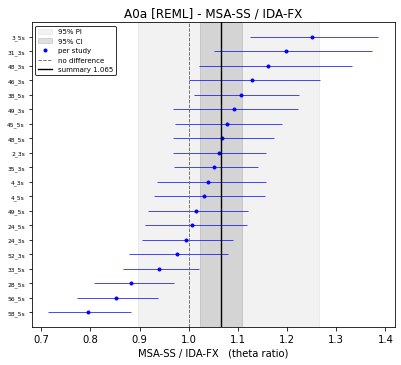

In [8]:
ax = fits_theta.forest("A0a", max_rows=20)

### 2.2 A1 — MSA site-specific vs MSA fixed set

The pure **record-set** effect: the analysis procedure is held constant and only the record selection changes. This is the contrast the study exists to measure.

#### 2.2.1 A1a - Diagonal Matrix
A1a is the one rung where a diagonal `V_known` is exactly right on the diagonal, since the two
arms use disjoint record sets and so $v_1[i] = v_a[i] + V_{bb}[g[i],g[i]]$ exactly. That is a
statement about the *diagonal* only — rows sharing a design still share $b_j$, which is what A1b
and A1c exist to handle and why A1a's $\tau^2$ is a baseline rather than a reportable number.

In [9]:
print(fits_theta["A1a"].summary())

A1a [REML]  MSA-SS / MSA-FX  (y1 = a - b, theta, n=120)
  summary effect   : 0.9895   (log -0.0105)
  95% CI           : 0.9445 - 1.0476     <- where the MEAN effect lies
  95% PI           : 0.8314 - 1.1777     <- where the NEXT case lands
  SE (superpop.)   : 0.00897   <- includes tau: a NEW structure
  SE (sampling)    : 0.02763   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.02807   <- 200 refits
    -> fitted with a DIAGONAL sampling covariance: the model-based SE omits the off-diagonal entirely, and the weights ignore that rows in a design share an arm.
  tau_u            : 0.0833   (a factor of 1.087)
  Q                : 426.70 on 119 df, p = 3e-36   (excess over null +307.70)
  I_sq             : 72.8%   [T^2 / (s^2 + T^2), REML T^2]   (secondary - see Borenstein Ch. 16: I_sq is a PROPORTION of variance that is real, and with small sampling variances it tends to 1 almost regardless)
  Site-specific MSA against fixed-set MSA: the pure record-set effect, with the anal

In [10]:
fits_theta["A1a"].het

{'Q': np.float64(426.70495063091624),
 'df': 119,
 'Q_df': np.float64(307.70495063091624),
 'p': 2.9982922620910074e-36,
 's_sq': 0.0025942549122988327,
 'T_sq': 0.006945121054820999,
 'T': np.float64(0.08333739289671233),
 'I_sq': 72.80477338097724}

#### 2.2.2 A1b - Building Groups

This model shows the effect of not considering the site term when using the full covariance model.

In [11]:
print(fits_theta["A1b"].summary())

A1b [REML]  MSA-SS / MSA-FX  (y1 = a - b, theta, n=120)
  summary effect   : 1.0327   (log +0.0322)
  95% CI           : 0.9888 - 1.0736     <- where the MEAN effect lies
  95% PI           : 0.8689 - 1.2273     <- where the NEXT case lands
  SE (superpop.)   : 0.02300   <- includes tau: a NEW structure
  SE (sampling)    : 0.01884   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.02044   <- 200 refits
  tau_d            : 0.0000   (a factor of 1.000)
  tau_u            : 0.0848   (a factor of 1.088)
  Q                : 426.70 on 119 df, p = 3e-36   (excess over null +307.70)
    -> p is nominal: Q uses the diagonal v, but rows here share sampling error (a common b_j / c_j), which inflates Q
  I_sq             : 73.5%   [T^2 / (s^2 + T^2), REML T^2]   (secondary - see Borenstein Ch. 16: I_sq is a PROPORTION of variance that is real, and with small sampling variances it tends to 1 almost regardless)
  Site-specific MSA against fixed-set MSA: the pure record-set effect, with th

#### 2.2.3 A1c - Crossed Structure: Buildings and Sites

In this model the between-study variance is split into building group effects, site effects and random effects. This is the first step in understanding what the between site variance is due to.

Rows in the same building group can be alike for two reasons:
1. a real design effect (i.e. they share a building which has a noticeable effect on the observed value of y1)
2. the value of b_j (MSA-FX for building j) has a large/noisy sampling variance and shared by all the rows with the same building design.

We can run two analyses. One with the diagonal V matrix and one with the full variance matrix. The V matrix tells the REML algorithm how much sampling variance (i.e. from the bootstrap fits) we have. If it is diagonal then there is no covariance between the sites/structure combinations being modelled. This means that REML does not know that multiple rows (site/structure combinations) share the same value of b_j and its associated sampling variance. 

If we use the full V-matrix (V_aa + ZV_bbZ') then we model the covariance in the sampling variance and the REML algorithm knows that some sites share designs and therefore a source of sampling variance. Doing an analysis with the full V-Matrix will then tell us if there is any actually a difference between the sites. Vaa contains covariance between rows due to both shared structures and shared sites. V_bb adds covariance due to shared structures.

The following A1c analysis uses the full V-Matrix

In [12]:
print(fits_theta["A1c"].summary())

A1c [REML]  MSA-SS / MSA-FX  (y1 = a - b, theta, n=120)
  summary effect   : 1.0051   (log +0.0051)
  95% CI           : 0.9669 - 1.0440     <- where the MEAN effect lies
  95% PI           : 0.8437 - 1.1975     <- where the NEXT case lands
  SE (superpop.)   : 0.02215   <- includes tau: a NEW structure
  SE (sampling)    : 0.01667   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.01926   <- 200 refits
  tau_d            : 0.0161   (a factor of 1.016)
  tau_s            : 0.0827   (a factor of 1.086)
  tau_u            : 0.0189   (a factor of 1.019)
  Q                : 426.70 on 119 df, p = 3e-36   (excess over null +307.70)
    -> p is nominal: Q uses the diagonal v, but rows here share sampling error (a common b_j / c_j), which inflates Q
  I_sq             : 74.2%   [T^2 / (s^2 + T^2), REML T^2]   (secondary - see Borenstein Ch. 16: I_sq is a PROPORTION of variance that is real, and with small sampling variances it tends to 1 almost regardless)
  Site-specific MSA against 

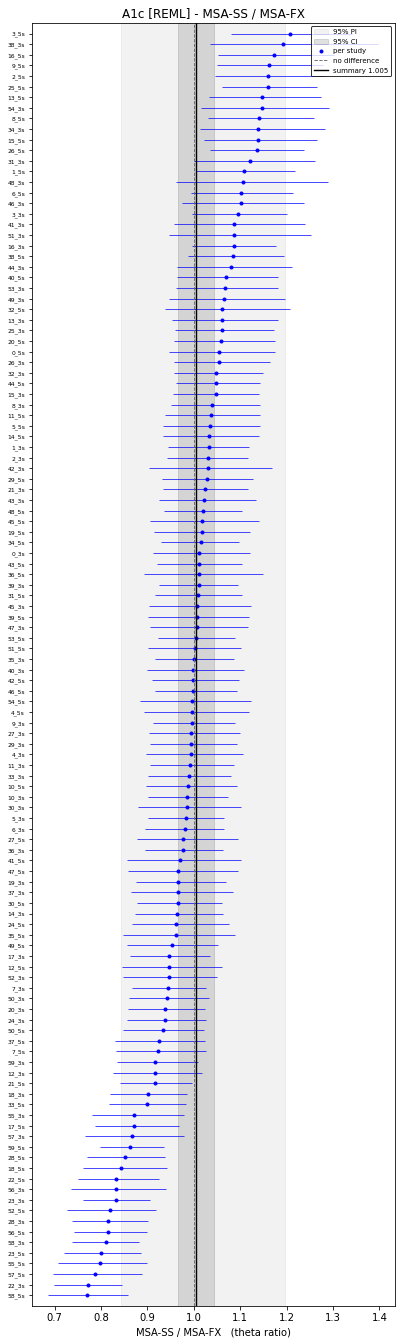

In [13]:
ax = fits_theta.forest("A1c")

The results of this analysis are:
1. $m_1$ is 1.0099 with a prediction interval of 0.844 - 1.208
1. $\tau_d$ is zero
2. $\tau_s$ is much larger (0.086) --> ~93% of the variance
3. $\tau_u$ is smaller (0.023) --> ~7% of the variance

The average effect across all sites and structures is 1.0099 (basically no difference between MSA-SS and MSA-FX),  indicating that a fixed record set (of a type similar to the FEMA-P695 record set) does not appear to be biased on average for the 60 representative European sites used in this study, however the 95% prediction interval is relatively wide 0.844 -> 1.208  (-16% to +21%). This indicates that the error at for an individual site (site/structure combination) may be quite large.

A variance decomposition shows that the variation due to differences in building designs is negligible (which is somewhat to be expected because the buildings are all relatively similar - 3s and 5s steel CBF structures.) The variation associated with between-site diffrences is ~93% of the total variance. The remaining 7% is the random effect

A regression analysis on this data would be useful for identifying parameters that can reduce the between-site variance. Such a regression model could also be used to provide a "correction factor" when using a fixed record set. 

**Be Careful** The large share in site variance is possibly due to the wide variation in site characteristics compared to the relatively narrow group of structures (3s and 5s steel CBFs). Variance share is related to the sampled range so the large range so have the more variance share is associated with it. That is possible why the sites look so dominant here. It is true in this case but we must be careful not to generalise it too far! --> see (Gelman & Hill Ch. 21, ~p. 459–463, approx.)

In [14]:
band = fits_theta.table(["A1a", "A1b", "A1c"])
band.loc[(slice(None), "REML"),
         ["contrast", "ratio", "se_boot", "ci_lo", "ci_hi"]].round(4)

,,contrast,ratio,se_boot,ci_lo,ci_hi
model,estimator,,,,,
A1a,REML,y1,0.9895,0.0281,0.9445,1.0476
A1b,REML,y1,1.0327,0.0204,0.9888,1.0736
A1c,REML,y1,1.0051,0.0193,0.9669,1.0440


The mean ratio shifts between models depending on the variance components considered and the if the full sampling matrix with covariance is considered or not. A1b is evidence that not including the site term in the model skews the results as the weights in the REML algorithm treat the within-site similarity as if it were sampling noise. --> A0 needs the same decomposition as well before conclusions can be drawn regarding the differences between MSA-SS and IDA-FX.

### 2.3 A2 — MSA fixed set vs IDA fixed set

Both arms use the same records, so the record effect cancels and what is left is the
**procedure** effect: stripe-count binomial MLE against lognormal-of-capacities.

Fitted at **51 rows**, because one row is one design — the fixed-set stripe IMLs come from the span of the fragility curve rather than from site hazard, so these arms depend on the design only (analysis_models.md §1(b)).

In [15]:
print(fits_theta["A2"].summary())

A2 [REML]  MSA-FX / IDA-FX  (y2 = b - c, theta, n=51)
  summary effect   : 1.0450   (log +0.0441)
  95% CI           : 1.0415 - 1.0501     <- where the MEAN effect lies
  95% PI           : 1.0243 - 1.0662     <- where the NEXT case lands
  SE (superpop.)   : 0.00245   <- includes tau: a NEW structure
  SE (sampling)    : 0.00156   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.00208   <- 200 refits
    -> bootstrap SE is 1.34x sqrt(w' V w); these should agree to Monte-Carlo error. The bootstrap is not carrying the covariance the fit was handed - check the replicate alignment, or raise n_boot if it is close.
  tau_u            : 0.0097   (a factor of 1.010)
  Q                : 37.94 on 50 df, p = 0.895   (excess over null -12.06)
    -> p is nominal: Q uses the diagonal v, but rows here share sampling error (a common b_j / c_j), which inflates Q
  I_sq             : 28.0%   [T^2 / (s^2 + T^2), REML T^2]   (secondary - see Borenstein Ch. 16: I_sq is a PROPORTION of variance t

$\tau$ for the DL fit goes to almost zero and the random-effects model approximates the fixed-effects one (`Q` minus the dfs is < 0 (-12.06)). That is to be expected: the structure itself, at least within this group of steel CBFs, has no effect on the ratio of median collapse capacity between MSA-FX and IDA-FX. When $\tau \approx 0$ the prediction interval collapses onto the confidence interval of the mean, since there is no between-design variation left for a new design to be drawn from. The REML results show that tau_u is not zero but the variance is very small $\tau \approx 0.0097$.

The mean (fixed) effect is about **1.045** — IDA *underestimates* the median capacity by roughly 4.5% relative to the MSA on the same records. The cause of this systematic under-estimation comes from the choice of the definition of the collapse IML in the HTF-IDA algorithm of Vamvatsikos & Cornell, not a property of the records. This is explore furth in §2.4.

### 2.4 The collapse bracket — IDA-FX read three ways

An IDA resolves each record's capacity only to a **bracket**: between the highest intensity that ran and the lowest that collapsed. Vamvatsikos and Cornell use the highest converging run as the collapse capacity, although they note that the average or the lowest non-converging run could also be used. Up until this point that is what I have been using as well. This section shows that this is the source of the ~4.5% bias seen in §2.3.

The A2 comparison (y2 = b - c) was made for 3 different definitions of c:
1. The *highest converging run* (standard IDA as proposed by Vamvatsikos and Cornell) --> A lower bound
2. The *lowest nonconverging run* --> an upper bound
3. The *geometric average* of 1. and 2. --> a middle value

In [16]:

band = fits_theta.table(["A2", "A2_avg", "A2_ub"])
band.loc[(slice(None), "REML"),
         ["contrast", "n", "ratio", "se_boot", "ci_lo", "ci_hi"]].round(4)

,,contrast,n,ratio,se_boot,ci_lo,ci_hi
model,estimator,,,,,,
A2,REML,y2,51,1.0450,0.0021,1.0415,1.0501
A2_avg,REML,y2_avg,51,1.0057,0.0023,1.0024,1.0112
A2_ub,REML,y2_ub,51,0.9680,0.0025,0.9643,0.9742


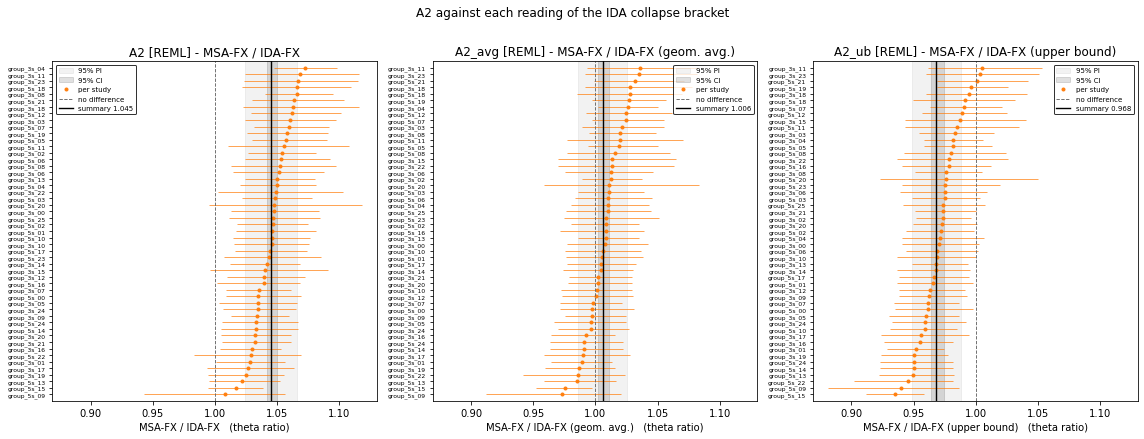

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharex=True)
estimator = "REML"
for ax, model_id in zip(axes, ("A2", "A2_avg", "A2_ub")):
    fits_theta.forest(model_id, estimator=estimator, ax=ax)
fig.suptitle("A2 against each reading of the IDA collapse bracket", y=1.01)
fig.tight_layout()
plt.show()

In [18]:
# Mean width of the IDA collapse bracket, ln(ub / lb), over every record of every design
# group. This is the number the discussion below compares with ln(M*_L) - ln(M*_U): under
# the uniform-in-log assumption the lower- and upper-bound effects should sit exactly one
# mean bracket width apart.

record_tags = fxr.record_stems(config.fx_record_files(cfg, FX))
iml_stem = (config.fx_dir(cfg, "proc_data", "structure_fragility_curves", FX)
            / "design_groups" / f"group_{FX}_collapse_imls.csv")

# The loader returns {n_storeys: table}; stack the storey tables into one 51 x 22 frame.
# The suffix picks the bracket end: "" is the lower bound, "_ub" the upper bound.
lb_imls, ub_imls = (
    pd.concat(mra.load_group_collapse_imls(
        iml_stem.with_name(f"{iml_stem.stem}_{IM_TAG}{suffix}.csv"), [3, 5], record_tags
    ).values())
    for suffix in ("", "_ub"))

# Log bracket width per (group, record). Every group has the same 22 records, so the
# grand mean equals nb 074's mean of per-group means.
log_bracket = np.log(ub_imls / lb_imls)
mean_bracket = log_bracket.to_numpy().mean()

print(f"Mean of the log of the ida collapse bracket: {mean_bracket:.4f}")
print(f"Mean ida collapse bracket in real units: {np.exp(mean_bracket):.4f}")
print(f"Estimated prediction error in real units: {0.5 * (1 - np.exp(mean_bracket)):.4f}")

Mean of the log of the ida collapse bracket: 0.0732
Mean ida collapse bracket in real units: 1.0759
Estimated prediction error in real units: -0.0379


From the forestplots and the mean effect size we can see that when we take the highest non collapsed iml in the IDA as our collapse capacity we are biasing the collapse capacity downwards compared to the MSA result. If we take the lowest collapsed iml then the collapse capacity is biased upwards compared to the MSA result. Finally, if the geometric average of the upper and lower bound iml is used then the results are unbiased with respect to the MSA results.

The bias of ~4.5% can be explained as follows:

The error between the "true" collapse value, $T_i$, and the lower bound value, $L_i$, for record $i$ is $$\varepsilon_i = \ln{\frac{T_i}{L_i}} \in \left(0, \ln\frac{U_i}{L_i}\right)$$ where $U_i$ is the upper bound value on the collapse capacity for the record $i$. From the definition of the IDA algorithm that has been implemented we know that the ratio $r=\frac{U_i}{L_i}\leq1.1$, i.e. the maximum difference between the upper and lower collapse bound is 10%. If we assume that $T_i$ is uniformly distributed on $\left(L_i, U_i\right)$ then $\varepsilon_i$ is uniformly distributed on $\left(0, \ln\frac{U_i}{L_i}\right) = (0, \ln{1.1})$. Calculating the expectation of $X\sim\mathcal{U}(a,b)$ is $$\mathbb{E}[X] = \frac{(a + b)}{2}$$ so the expectation of $\varepsilon$ is $$\mathbb{E}[\varepsilon_i] = \frac{(0 + \ln{1.1})}{2} = 0.04766$$ taking the exponential converts this into real units and we get 1.0488 or a 4.9% underestimation by IDA. Following this logic is it clear that if we substitute $U_i$ for $L_i$ then we would expected the same error just in the other direction, and substituting the geometric average for $L_i$ we would get no expected error.

The cell above calculates the mean collapse bracket width across all structures and records: 7.59% over all 51 groups. This is less than the 10% assumed above because the IDA algorithm used makes the trace step the minimum of 1/3 the distance between the last noncollapse iml and the lowest collapse iml or 10% of the last noncollapse iml. This means that in some cases the band width is less than 10% which drags down the mean. Halving this mean collapse bracket value gives and expected error (assuming a uniform distribution) of approximately 3.8%, which is smaller than the ~4.5% that we see from the meta analysis. There is ~0.6% error remaining.

Based on the uniform assumption we would expect the average of the log of the mean effects of the upper and lower collapse imls to be zero. $$0.5(\ln{M^*_L}+\ln{M^*_U}) = 0.5(\ln{1.045} + \ln{0.968}) = 0.00575$$ This is not zero, which indicates some level of bias. The bias is approximately $3.2\times SE$ ($SE = 0.0018$ from the bootstrap). The residual is therefore significantly different from zero at 95% confidence, however it is small and of little practical significance. This calculation is verified by looking at the A2_avg directly. This 0.00575 is the approximate 0.6% error above. It could be due to several things:
1. The true capacity sits above the log midpoint (i.e. it is not uniformly distributed)
2. The MSA estimator is slightly biased due to the finite stripe counts. `nb 070` shows that this is small and would acocunt for some but not all. 

The conclusions from this investigation are:
1. The the HTF algorithm as implemented by Vamvatsikos and Cornell (taking the highest noncollapsing IML) results in an ~4.5% underestimation in the median collapse capacity compared to MSA results with the same record set. Vamvatsikos says that the average or the upper bound would also be ok choices.
2. If this difference is corrected for i.e. the geometric average of the upper and lower bound is used to predict the collapse capacity then there is no meaningful difference in the values of median fragility obtained from IDA and MSA. (based on the structures that we have assessed here)

What does this mean for the rest of my models?
1. We can redfine the collapse point of the IDA-FX and then use the redefined collapse capacities to better estimate the difference between MSA-SS and IDA-FX 

### 2.5 A0b — MSA site-specific vs IDA fixed set : Avg Collapse IML

A0b_hb [REML]  [hybrid bootstrap]  MSA-SS / IDA-FX (geom. avg.)  (y0_avg = a - c_avg, theta, n=120)
  summary effect   : 1.0265   (log +0.0261)
  95% CI           : 0.9801 - 1.0714     <- where the MEAN effect lies, for the POPULATION of sites and designs (effects redrawn)
  95% PI           : 0.8636 - 1.2201     <- where the NEXT case lands
  SE (superpop.)   : 0.02298   <- includes tau: a NEW structure
  SE (sampling)    : 0.02008   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.02266   <- 200 refits, hybrid: compare with SE (superpop.)
  tau_u            : 0.0843   (a factor of 1.088)   95% CI 0.0713 - 0.0966, 0% of replicates at 0
  Q                : 465.96 on 119 df, p = 1.5e-42   (excess over null +346.96)
    -> p is nominal: Q uses the diagonal v, but rows here share sampling error (a common b_j / c_j), which inflates Q
  I_sq             : 74.9%   [T^2 / (s^2 + T^2), REML T^2]   (secondary - see Borenstein Ch. 16: I_sq is a PROPORTION of variance that is real, and w

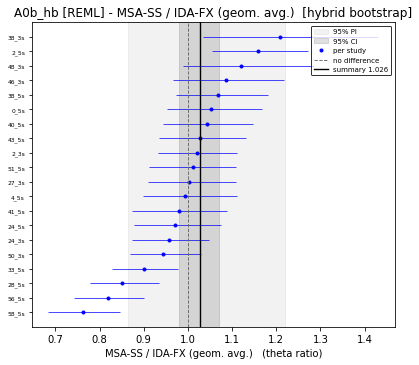

In [19]:
print(fits_theta["A0b_hb"].summary())
ax = fits_theta.forest("A0b_hb", max_rows=20)

### 2.6 A0c — MSA site-specific vs IDA fixed set : Avg Collapse IML and Decomposed

A0c [REML]  MSA-SS / IDA-FX (geom. avg.)  (y0_avg = a - c_avg, theta, n=120)
  summary effect   : 1.0068   (log +0.0067)
  95% CI           : 0.9682 - 1.0480     <- where the MEAN effect lies
  95% PI           : 0.8448 - 1.1997     <- where the NEXT case lands
  SE (superpop.)   : 0.02279   <- includes tau: a NEW structure
  SE (sampling)    : 0.01858   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.02026   <- 200 refits
  tau_d            : 0.0069   (a factor of 1.007)
  tau_s            : 0.0836   (a factor of 1.087)
  tau_u            : 0.0197   (a factor of 1.020)
  Q                : 465.96 on 119 df, p = 1.5e-42   (excess over null +346.96)
    -> p is nominal: Q uses the diagonal v, but rows here share sampling error (a common b_j / c_j), which inflates Q
  I_sq             : 75.7%   [T^2 / (s^2 + T^2), REML T^2]   (secondary - see Borenstein Ch. 16: I_sq is a PROPORTION of variance that is real, and with small sampling variances it tends to 1 almost regardless)
  A0a

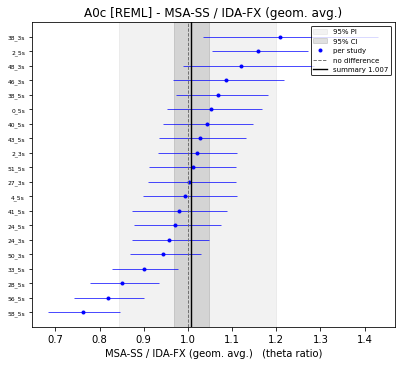

In [20]:
print(fits_theta["A0c"].summary())
ax = fits_theta.forest("A0c", max_rows=20)

#### Trends in the Random Effects

Plotting the site random effects against the covariates that I want to use from my regression will show me if there is a pattern to find or not.

In [21]:
A0c_fit = fits_theta["A0c"]
A0c_re = A0c_fit.random_effects()
covariates = ["d_ln_saratio_mean_rtp5000", "d_ln_saratio_sigma_rtp5000", "d_ln_ds595_mean_rtp5000", "d_ln_ds595_sigma_rtp5000", "ln_T1"]
covariate_data = A0c_fit.contrast.rows[covariates]
df = A0c_re.rows.join(covariate_data)
df.head()

y     fixed    design      site       row  sampling design_group_id  structure_id  d_ln_saratio_mean_rtp5000  d_ln_saratio_sigma_rtp5000  d_ln_ds595_mean_rtp5000  \
site n_storeys                                                                                                                                                                             
0    3          0.019935  0.006747 -0.000486  0.023759  0.001588 -0.011673     group_3s_00             0                  -0.080220                   -0.048632                 0.052246   
     5          0.050867  0.006747  0.002245  0.023759 -0.000263  0.018380     group_5s_00            25                   0.013126                    0.005714                 0.052246   
1    3          0.020989  0.006747 -0.000327  0.066467 -0.001417 -0.050480     group_3s_01             1                  -0.026056                   -0.042738                -0.313752   
     5          0.100763  0.006747  0.002245  0.066467  0.005124  0.020181     group_5s_00            25                   0.038231                   -0.004736                -0.313752   
2    3          0.020563  0.006747 -0.000327  0.078666 -0.008514 -0.056009     group_3s_01             1                  -0.005047                   -0.039141                -0.310230   

                d_ln_ds595_sigma_rtp5000     ln_T1  
site n_storeys                                      
0    3                          0.219682 -0.430955  
     5                          0.219682 -0.093010  
1    3                         -0.028731 -0.489860  
     5                         -0.028731 -0.093010  
2    3                         -0.046373 -0.489860

In [22]:
A0c_fit.contrast.rows.columns

Index(['structure_id', 'tag', 'design_group_id', 'n_sites_in_group', 'is_representative', 'msa_fx_theta', 'msa_fx_log_theta', 'msa_fx_theta_bc', 'msa_fx_log_theta_bc', 'msa_fx_var_theta',
       'msa_fx_var_log_theta', 'msa_fx_log_theta_bias', 'msa_fx_n_obs', 'ida_fx_theta', 'ida_fx_log_theta', 'ida_fx_theta_bc', 'ida_fx_log_theta_bc', 'ida_fx_var_theta', 'ida_fx_var_log_theta',
       'ida_fx_log_theta_bias', 'ida_fx_n_obs', 'ida_ub_theta', 'ida_ub_log_theta', 'ida_ub_theta_bc', 'ida_ub_log_theta_bc', 'ida_ub_var_theta', 'ida_ub_var_log_theta', 'ida_ub_log_theta_bias',
       'ida_ub_n_obs', 'ida_avg_theta', 'ida_avg_log_theta', 'ida_avg_theta_bc', 'ida_avg_log_theta_bc', 'ida_avg_var_theta', 'ida_avg_var_log_theta', 'ida_avg_log_theta_bias', 'ida_avg_n_obs',
       'msa_ss_theta', 'msa_ss_log_theta', 'msa_ss_theta_bc', 'msa_ss_log_theta_bc', 'msa_ss_var_theta', 'msa_ss_var_log_theta', 'msa_ss_log_theta_bias', 'msa_ss_n_obs', 'd_ln_saratio_mean_rtp475',
       'd_ln_saratio_sigma_rtp4

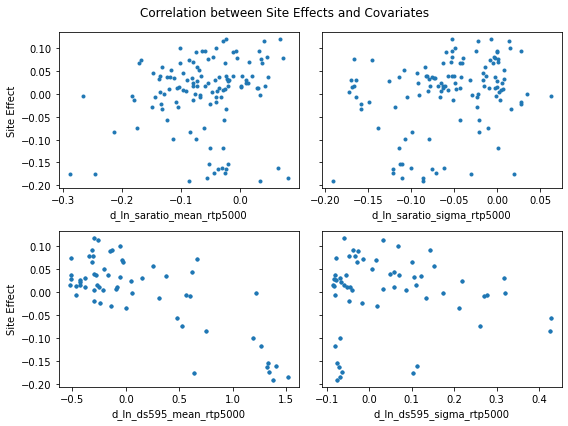

In [23]:
fig, axs_mat = plt.subplots(2, 2, figsize=(8, 6), sharey=True)

axs = axs_mat.flatten()

for ax, cov in zip(axs, covariates):
    ax.plot(df[cov], df["site"], marker=".", ls="none")
    ax.set_xlabel(cov)

axs_mat[0, 0].set_ylabel("Site Effect")
axs_mat[1, 0].set_ylabel("Site Effect")
fig.suptitle("Correlation between Site Effects and Covariates")
fig.tight_layout()

Looking at the plot above it appears that the difference between the expected duration at the site and the fixed record set has the strongest correlation with the estimated site effects. The other covariates, particularly the difference in SARatio are uncorrelated. This could be due to the fact that by using AvgSA as our conditional intensity measure we have already accounted for spectral shape (Eads et al. 2016 and Kohrangi et al. 2018?) in our intensity measure.

The plots of SARatio are not completely fair though because two rows always share the same effect value. We can plot the site effect + random effect against d_ln_saratio to fix this.

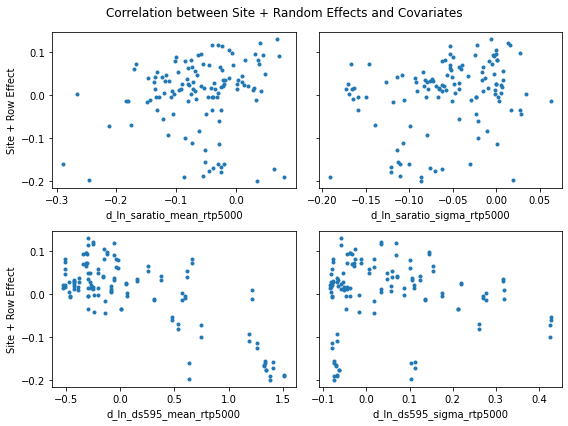

In [24]:
fig, axs_mat = plt.subplots(2, 2, figsize=(8, 6), sharey=True)

axs = axs_mat.flatten()

for ax, cov in zip(axs, covariates):
    ax.plot(df[cov], df["site"] + df["row"], marker=".", ls="none")
    ax.set_xlabel(cov)

axs_mat[0, 0].set_ylabel("Site + Row Effect")
axs_mat[1, 0].set_ylabel("Site + Row Effect")
fig.suptitle("Correlation between Site + Random Effects and Covariates")
fig.tight_layout()

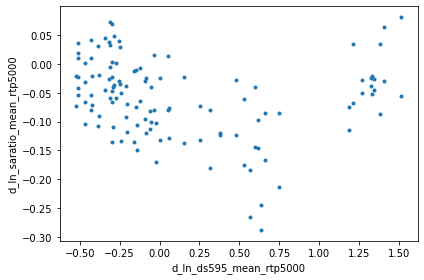

In [25]:
fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(df["d_ln_ds595_mean_rtp5000"], df["d_ln_saratio_mean_rtp5000"], marker=".", ls="none")
ax.set_xlabel("d_ln_ds595_mean_rtp5000")
ax.set_ylabel("d_ln_saratio_mean_rtp5000")
fig.tight_layout()

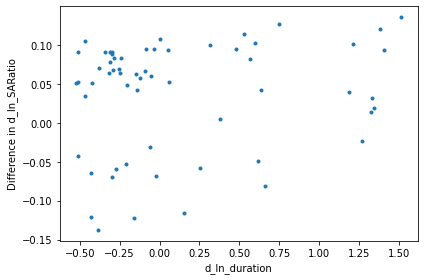

In [26]:
# This plot is the difference between SARatios for the 5s and 3s structures at a site
# against the expected record duration at a site. If a pattern is present then there 
# is confounding between the two variables.

saratio_wide = df["d_ln_saratio_mean_rtp5000"].unstack("n_storeys")
delta_S = (saratio_wide[5] - saratio_wide[3]).rename("delta_SARatio")

dur_wide = df["d_ln_ds595_mean_rtp5000"].unstack("n_storeys")
D_k = dur_wide[3].rename("D_k")
site_df = pd.concat([delta_S, D_k], axis=1)

fig, ax = plt.subplots(figsize=(6, 4))

effect = "sampling"
ax.plot(site_df["D_k"], site_df["delta_SARatio"], marker=".", ls="none")
ax.set_xlabel("d_ln_duration")
ax.set_ylabel(f"Difference in d_ln_SARatio")
fig.tight_layout()

### 2.7 A0d — MSA site-specific vs IDA fixed set : Lower Collapse IML and Decomposed

A0d [REML]  MSA-SS / IDA-FX  (y0 = a - c, theta, n=120)
  summary effect   : 1.0441   (log +0.0431)
  95% CI           : 1.0050 - 1.0866     <- where the MEAN effect lies
  95% PI           : 0.8759 - 1.2445     <- where the NEXT case lands
  SE (superpop.)   : 0.02277   <- includes tau: a NEW structure
  SE (sampling)    : 0.01849   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.02033   <- 200 refits
  tau_d            : 0.0046   (a factor of 1.005)
  tau_s            : 0.0838   (a factor of 1.087)
  tau_u            : 0.0200   (a factor of 1.020)
  Q                : 457.29 on 119 df, p = 3.83e-41   (excess over null +338.29)
    -> p is nominal: Q uses the diagonal v, but rows here share sampling error (a common b_j / c_j), which inflates Q
  I_sq             : 75.4%   [T^2 / (s^2 + T^2), REML T^2]   (secondary - see Borenstein Ch. 16: I_sq is a PROPORTION of variance that is real, and with small sampling variances it tends to 1 almost regardless)
  A0a with the bewteen-st

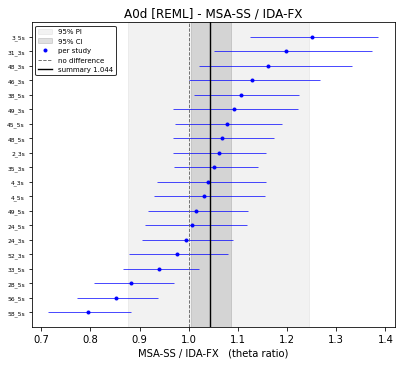

In [27]:
print(fits_theta["A0d"].summary())
ax = fits_theta.forest("A0d", max_rows=20)

### 2.8 A3 — Regression Analysis between MSA-SS and IDA-FX

#### 2.8.1 A3a - Site Covariates

In [28]:
print(fits_theta["A3a"].summary())

A3a [REML]  MSA-SS / IDA-FX (geom. avg.)  (y0_avg = a - c_avg, theta, n=120)
  summary effect   : 0.9942   (log -0.0058)
  95% CI           : 0.9571 - 1.0353     <- where the MEAN effect lies
  95% PI           : 0.8963 - 1.1027     <- where the NEXT case lands
  SE (superpop.)   : 0.02096   <- includes tau: a NEW structure
  SE (sampling)    : 0.01808   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.01994   <- 200 refits
  tau_d            : 0.0129   (a factor of 1.013)
  tau_s            : 0.0431   (a factor of 1.044)
  tau_u            : 0.0177   (a factor of 1.018)
  covariates (log scale; slope per SD of covariate):
    d_ln_saratio_mean_rtp5000
      coefficient  : +0.00665  SE 0.00730   (z = +0.91, p = 0.362)   <- SE includes tau
      SE (sampling): 0.00458
      SE (bootstr.): 0.00501   95% CI -0.00269 to +0.01716
      per unit     : +0.09570  SE 0.10498   (covariate SD = 0.06951)
    d_ln_ds595_mean_rtp5000
      coefficient  : -0.07026  SE 0.00695   (z = -10.11, p

As a first look we can see that the SARatio is not statistically significant at the 5% level and does not provide us with much extra information. Conversely, including the duration significantly reduces the between-site variance and narrows the prediction interval to +/- ~10%

Not every site had optimised DS_595 stripes. As a result the actual distribution of the records may differ from the target gcims. In another notebook I have calculated the weighted KS-statistic (i.e. the average difference between the target and the actual records used) for each site/structure combination. Including this misfit as a covariate in the model allows me to see if it has any effect.

##### A3aa

In [29]:
print(fits_theta["A3aa"].summary())

A3aa [REML]  MSA-SS / IDA-FX (geom. avg.)  (y0_avg = a - c_avg, theta, n=120)
  summary effect   : 0.9927   (log -0.0073)
  95% CI           : 0.9569 - 1.0340     <- where the MEAN effect lies
  95% PI           : 0.9008 - 1.0941     <- where the NEXT case lands
  SE (superpop.)   : 0.02058   <- includes tau: a NEW structure
  SE (sampling)    : 0.01784   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.01972   <- 200 refits
  tau_d            : 0.0111   (a factor of 1.011)
  tau_s            : 0.0393   (a factor of 1.040)
  tau_u            : 0.0187   (a factor of 1.019)
  covariates (log scale; slope per SD of covariate):
    d_ln_saratio_mean_rtp5000
      coefficient  : +0.00910  SE 0.00706   (z = +1.29, p = 0.197)   <- SE includes tau
      SE (sampling): 0.00444
      SE (bootstr.): 0.00506   95% CI -0.00050 to +0.01986
      per unit     : +0.13088  SE 0.10152   (covariate SD = 0.06951)
    d_ln_ds595_mean_rtp5000
      coefficient  : -0.08022  SE 0.00763   (z = -10.52, 

##### A3ab

In [30]:
print(fits_theta["A3ab"].summary())

A3ab [REML]  MSA-SS / IDA-FX (geom. avg.)  (y0_avg = a - c_avg, theta, n=120)
  summary effect   : 0.9905   (log -0.0095)
  95% CI           : 0.9556 - 1.0332     <- where the MEAN effect lies
  95% PI           : 0.8976 - 1.0930     <- where the NEXT case lands
  SE (superpop.)   : 0.02043   <- includes tau: a NEW structure
  SE (sampling)    : 0.01773   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.01973   <- 200 refits
  tau_d            : 0.0111   (a factor of 1.011)
  tau_s            : 0.0416   (a factor of 1.042)
  tau_u            : 0.0153   (a factor of 1.015)
  covariates (log scale; slope per SD of covariate):
    d_ln_saratio_mean_unif
      coefficient  : +0.00865  SE 0.00797   (z = +1.09, p = 0.278)   <- SE includes tau
      SE (sampling): 0.00516
      SE (bootstr.): 0.00534   95% CI -0.00364 to +0.01663
      per unit     : +0.11785  SE 0.10860   (covariate SD = 0.07337)
    d_ln_ds595_mean_unif
      coefficient  : -0.07346  SE 0.00681   (z = -10.79, p = 3.

##### A3ac

In [31]:
print(fits_theta["A3ac"].summary())

A3ac [REML]  MSA-SS / IDA-FX (geom. avg.)  (y0_avg = a - c_avg, theta, n=120)
  summary effect   : 0.9967   (log -0.0033)
  95% CI           : 0.9592 - 1.0391     <- where the MEAN effect lies
  95% PI           : 0.9137 - 1.0872     <- where the NEXT case lands
  SE (superpop.)   : 0.02095   <- includes tau: a NEW structure
  SE (sampling)    : 0.01817   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.01960   <- 200 refits
  tau_d            : 0.0189   (a factor of 1.019)
  tau_s            : 0.0292   (a factor of 1.030)
  tau_u            : 0.0183   (a factor of 1.018)
  covariates (log scale; slope per SD of covariate):
    d_ln_saratio_mean_unif
      coefficient  : +0.00321  SE 0.00756   (z = +0.42, p = 0.671)   <- SE includes tau
      SE (sampling): 0.00484
      SE (bootstr.): 0.00518   95% CI -0.00842 to +0.01123
      per unit     : +0.04370  SE 0.10301   (covariate SD = 0.07337)
    d_ln_ds595_mean_unif
      coefficient  : -0.09518  SE 0.00798   (z = -11.93, p = 8.

##### A3ad

In [32]:
print(fits_theta["A3ad"].summary())

A3ad [REML]  MSA-SS / IDA-FX (geom. avg.)  (y0_avg = a - c_avg, theta, n=120)
  summary effect   : 1.0000   (log +0.0000)
  95% CI           : 0.9619 - 1.0420     <- where the MEAN effect lies
  95% PI           : 0.9260 - 1.0800     <- where the NEXT case lands
  SE (superpop.)   : 0.01991   <- includes tau: a NEW structure
  SE (sampling)    : 0.01738   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.01910   <- 200 refits
  tau_d            : 0.0135   (a factor of 1.014)
  tau_s            : 0.0258   (a factor of 1.026)
  tau_u            : 0.0172   (a factor of 1.017)
  covariates (log scale; slope per SD of covariate):
    d_ln_saratio_mean_fisher
      coefficient  : -0.00099  SE 0.00692   (z = -0.14, p = 0.887)   <- SE includes tau
      SE (sampling): 0.00472
      SE (bootstr.): 0.00513   95% CI -0.01278 to +0.00747
      per unit     : -0.01358  SE 0.09523   (covariate SD = 0.07267)
    d_ln_ds595_mean_fisher
      coefficient  : -0.10155  SE 0.00715   (z = -14.21, p 

##### A3ae

In [33]:
print(fits_theta["A3ae"].summary())

A3ae [REML]  MSA-SS / IDA-FX (geom. avg.)  (y0_avg = a - c_avg, theta, n=120)
  summary effect   : 0.9924   (log -0.0076)
  95% CI           : 0.9577 - 1.0342     <- where the MEAN effect lies
  95% PI           : 0.9101 - 1.0822     <- where the NEXT case lands
  SE (superpop.)   : 0.02049   <- includes tau: a NEW structure
  SE (sampling)    : 0.01778   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.01948   <- 200 refits
  tau_d            : 0.0156   (a factor of 1.016)
  tau_s            : 0.0302   (a factor of 1.031)
  tau_u            : 0.0194   (a factor of 1.020)
  covariates (log scale; slope per SD of covariate):
    d_ln_saratio_mean_unif_corrected
      coefficient  : -0.00232  SE 0.00691   (z = -0.34, p = 0.737)   <- SE includes tau
      SE (sampling): 0.00450
      SE (bootstr.): 0.00490   95% CI -0.01303 to +0.00446
      per unit     : -0.02996  SE 0.08933   (covariate SD = 0.07739)
    d_ln_ds595_mean_unif_corrected
      coefficient  : -0.08297  SE 0.00627  

#### 2.8.2 A3b - Structure Covariates

In [34]:
print(fits_theta["A3b"].summary())

A3b [REML]  MSA-SS / IDA-FX (geom. avg.)  (y0_avg = a - c_avg, theta, n=120)
  summary effect   : 1.0057   (log +0.0057)
  95% CI           : 0.9678 - 1.0475     <- where the MEAN effect lies
  95% PI           : 0.8437 - 1.1988     <- where the NEXT case lands
  SE (superpop.)   : 0.02280   <- includes tau: a NEW structure
  SE (sampling)    : 0.01863   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.02039   <- 200 refits
  tau_d            : 0.0054   (a factor of 1.005)
  tau_s            : 0.0838   (a factor of 1.087)
  tau_u            : 0.0199   (a factor of 1.020)
  covariates (log scale; slope per SD of covariate):
    ln_T1
      coefficient  : -0.00873  SE 0.01286   (z = -0.68, p = 0.497)   <- SE includes tau
      SE (sampling): 0.01137
      SE (bootstr.): 0.01268   95% CI -0.02936 to +0.01823
      per unit     : -0.02823  SE 0.04160   (covariate SD = 0.3092)
  Regression analysis of the difference between site-specific MSA and IDA FX using the average collapse IML

#### 2.8.3 A3c - All Covariates

In [35]:
print(fits_theta["A3c"].summary())

A3c [REML]  MSA-SS / IDA-FX (geom. avg.)  (y0_avg = a - c_avg, theta, n=120)
  summary effect   : 0.9909   (log -0.0091)
  95% CI           : 0.9537 - 1.0352     <- where the MEAN effect lies
  95% PI           : 0.8931 - 1.0995     <- where the NEXT case lands
  SE (superpop.)   : 0.02128   <- includes tau: a NEW structure
  SE (sampling)    : 0.01834   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.02030   <- 200 refits
  tau_d            : 0.0132   (a factor of 1.013)
  tau_s            : 0.0432   (a factor of 1.044)
  tau_u            : 0.0176   (a factor of 1.018)
  covariates (log scale; slope per SD of covariate):
    d_ln_saratio_mean_rtp5000
      coefficient  : +0.00773  SE 0.00740   (z = +1.04, p = 0.296)   <- SE includes tau
      SE (sampling): 0.00466
      SE (bootstr.): 0.00507   95% CI -0.00235 to +0.01826
      per unit     : +0.11114  SE 0.10640   (covariate SD = 0.06951)
    d_ln_ds595_mean_rtp5000
      coefficient  : -0.06958  SE 0.00699   (z = -9.96, p 

## 3.0 Statistical Models for $\beta$

In [36]:
fits_beta = fm.ModelRegistry(beta)
N_BOOT = 200 # theta.k          # all of them - these are the reportable fits

# Every beta model the sections below read (§3.1 - §3.4).
BETA_MODELS = [
    "A0b_bc_hb", "A0c_bc", "A0c_bc_hb",                 # 3.1  A0
    "A2_bc_hb", "A2_avg_bc_hb", "A2_ub_bc_hb",          # 3.3  A2, three bracket readings
    "A3a_bc_hb", "A3ac_bc_hb", "A3ad_bc_hb", "A3ae_bc_hb",   # 3.4  A3
]
for model_id in BETA_MODELS:
    fits_beta.fit(model_id, n_boot=N_BOOT, verbose=True)

  A0b_bc_hb [REML]: outer bootstrap over 200 replicates (hybrid)...
  A0c_bc [REML]: outer bootstrap over 200 replicates...
  A0c_bc_hb [REML]: outer bootstrap over 200 replicates (hybrid)...
  A2_bc_hb [REML]: outer bootstrap over 200 replicates (hybrid)...
  A2_avg_bc_hb [REML]: outer bootstrap over 200 replicates (hybrid)...
  A2_ub_bc_hb [REML]: outer bootstrap over 200 replicates (hybrid)...
  A3a_bc_hb [REML]: outer bootstrap over 200 replicates (hybrid)...
  A3ac_bc_hb [REML]: outer bootstrap over 200 replicates (hybrid)...
  A3ad_bc_hb [REML]: outer bootstrap over 200 replicates (hybrid)...
  A3ae_bc_hb [REML]: outer bootstrap over 200 replicates (hybrid)...


### 3.1 A0

#### 3.1.1 A0b

A0b_bc_hb [REML]  [bias-corrected estimates]  [hybrid bootstrap]  MSA-SS / IDA-FX (geom. avg.)  (y0_avg = a - c_avg, beta, n=120)
  summary effect   : 1.0131   (log +0.0130)
  95% CI           : 0.9301 - 1.1229     <- where the MEAN effect lies, for the POPULATION of sites and designs (effects redrawn)
    -> percentile interval of the bias-corrected estimator: replicates shifted by -(2b + s), see FragilityData.replicate_shift
  95% PI           : 0.8367 - 1.2267     <- where the NEXT case lands
  SE (superpop.)   : 0.04544   <- includes tau: a NEW structure
  SE (sampling)    : 0.04367   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.04981   <- 200 refits, hybrid: compare with SE (superpop.)
  tau_u            : 0.0828   (a factor of 1.086)   95% CI 0.0273 - 0.1271, 1% of replicates at 0
  Q                : 166.72 on 119 df, p = 0.00257   (excess over null +47.72)
    -> p is nominal: Q uses the diagonal v, but rows here share sampling error (a common b_j / c_j), which infl

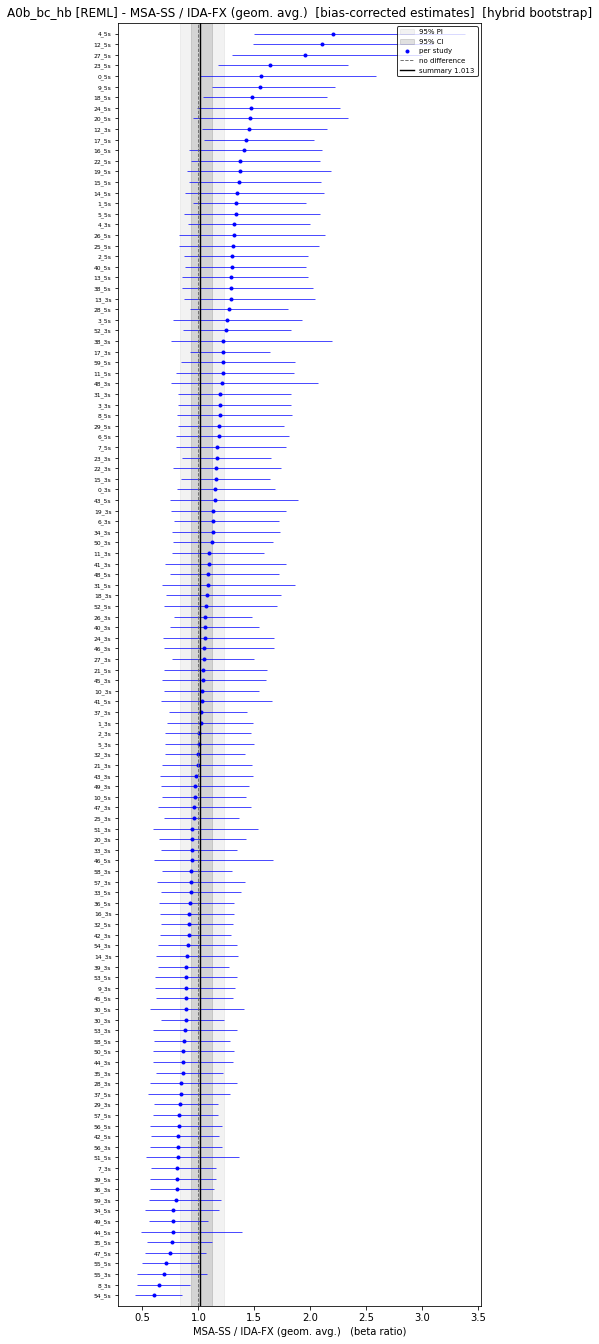

In [37]:
print(fits_beta["A0b_bc_hb"].summary())
ax = fits_beta.forest("A0b_bc_hb")

#### 3.1.1 A0c

A0c_bc [REML]  [bias-corrected estimates]  MSA-SS / IDA-FX (geom. avg.)  (y0_avg = a - c_avg, beta, n=120)
  summary effect   : 1.0158   (log +0.0157)
  95% CI           : 0.9284 - 1.1131     <- where the MEAN effect lies
    -> percentile interval of the bias-corrected estimator: replicates shifted by -(2b + s), see FragilityData.replicate_shift
  95% PI           : 0.8166 - 1.2636     <- where the NEXT case lands
  SE (superpop.)   : 0.04703   <- includes tau: a NEW structure
  SE (sampling)    : 0.04406   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.04798   <- 200 refits
  tau_d            : 0.0000   (a factor of 1.000)
  tau_s            : 0.0992   (a factor of 1.104)
  tau_u            : 0.0000   (a factor of 1.000)
  Q                : 166.72 on 119 df, p = 0.00257   (excess over null +47.72)
    -> p is nominal: Q uses the diagonal v, but rows here share sampling error (a common b_j / c_j), which inflates Q
  I_sq             : 20.2%   [T^2 / (s^2 + T^2), REML T^2]  

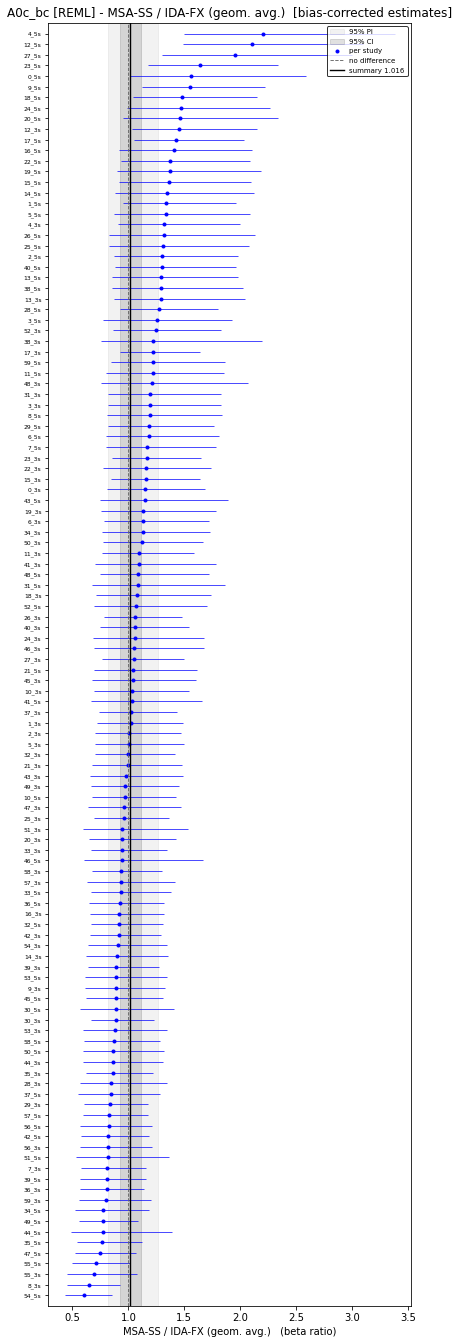

In [38]:
print(fits_beta["A0c_bc"].summary())
ax = fits_beta.forest("A0c_bc")

A0c_bc_hb [REML]  [bias-corrected estimates]  [hybrid bootstrap]  MSA-SS / IDA-FX (geom. avg.)  (y0_avg = a - c_avg, beta, n=120)
  summary effect   : 1.0158   (log +0.0157)
  95% CI           : 0.9258 - 1.1248     <- where the MEAN effect lies, for the POPULATION of sites and designs (effects redrawn)
    -> percentile interval of the bias-corrected estimator: replicates shifted by -(2b + s), see FragilityData.replicate_shift
  95% PI           : 0.8155 - 1.2654     <- where the NEXT case lands
  SE (superpop.)   : 0.04703   <- includes tau: a NEW structure
  SE (sampling)    : 0.04406   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.04961   <- 200 refits, hybrid: compare with SE (superpop.)
  tau_d            : 0.0000   (a factor of 1.000)   95% CI 0.0000 - 0.0825, 63% of replicates at 0
  tau_s            : 0.0992   (a factor of 1.104)   95% CI 0.0000 - 0.1279, 3% of replicates at 0
  tau_u            : 0.0000   (a factor of 1.000)   95% CI 0.0000 - 0.0879, 72% of replicat

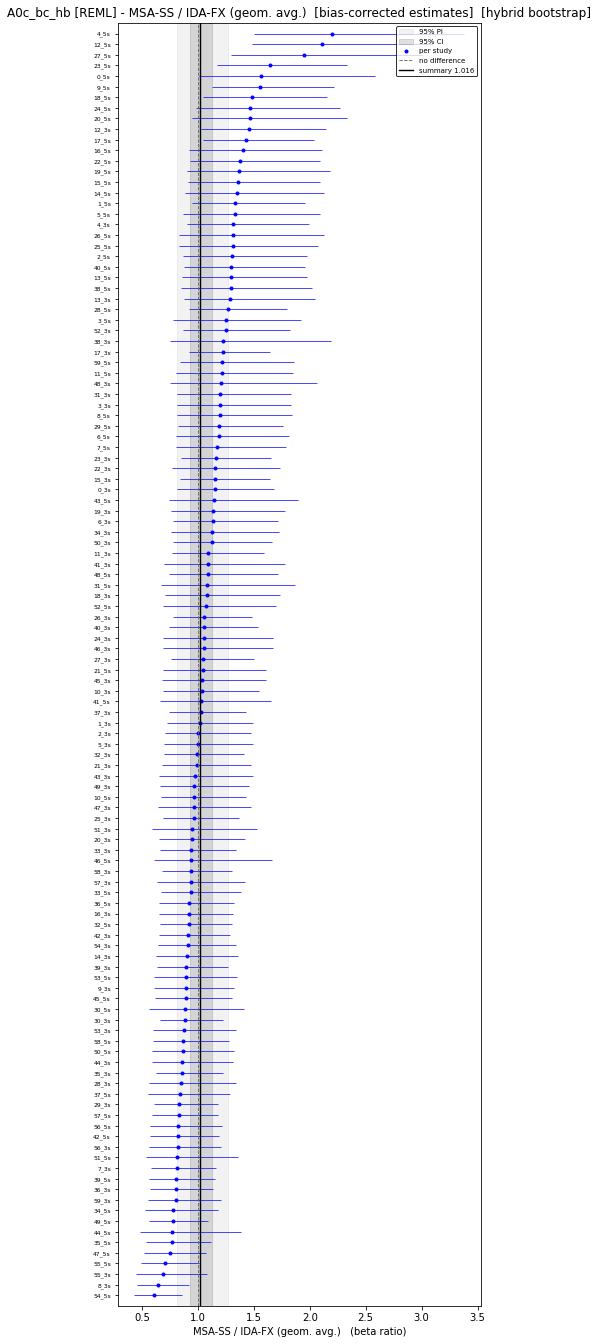

In [39]:
print(fits_beta["A0c_bc_hb"].summary())
ax = fits_beta.forest("A0c_bc_hb")

### 3.2 A1

### 3.3 A2

In [40]:
print(fits_beta["A2_bc_hb"].summary())

A2_bc_hb [REML]  [bias-corrected estimates]  [hybrid bootstrap]  MSA-FX / IDA-FX  (y2 = b - c, beta, n=51)
  summary effect   : 0.9930   (log -0.0070)
  95% CI           : 0.9499 - 1.0429     <- where the MEAN effect lies, for the POPULATION of sites and designs (effects redrawn)
    -> percentile interval of the bias-corrected estimator: replicates shifted by -(2b + s), see FragilityData.replicate_shift
  95% PI           : 0.8309 - 1.1868     <- where the NEXT case lands
  SE (superpop.)   : 0.02292   <- includes tau: a NEW structure
  SE (sampling)    : 0.01507   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.02333   <- 200 refits, hybrid: compare with SE (superpop.)
  tau_u            : 0.0856   (a factor of 1.089)   95% CI 0.0617 - 0.1133, 0% of replicates at 0
  Q                : 47.93 on 50 df, p = 0.557   (excess over null -2.07)
    -> p is nominal: Q uses the diagonal v, but rows here share sampling error (a common b_j / c_j), which inflates Q
  I_sq             : 

In [41]:
band = fits_beta.table(["A2_bc_hb", "A2_avg_bc_hb", "A2_ub_bc_hb"])
band.loc[(slice(None), "REML"),
         ["contrast", "n", "ratio", "se_boot", "ci_lo", "ci_hi"]].round(4)

,,contrast,n,ratio,se_boot,ci_lo,ci_hi
model,estimator,,,,,,
A2_bc_hb,REML,y2,51,0.9930,0.0233,0.9499,1.0429
A2_avg_bc_hb,REML,y2_avg,51,0.9966,0.0246,0.9504,1.0469
A2_ub_bc_hb,REML,y2_ub,51,0.9928,0.0261,0.9463,1.0405


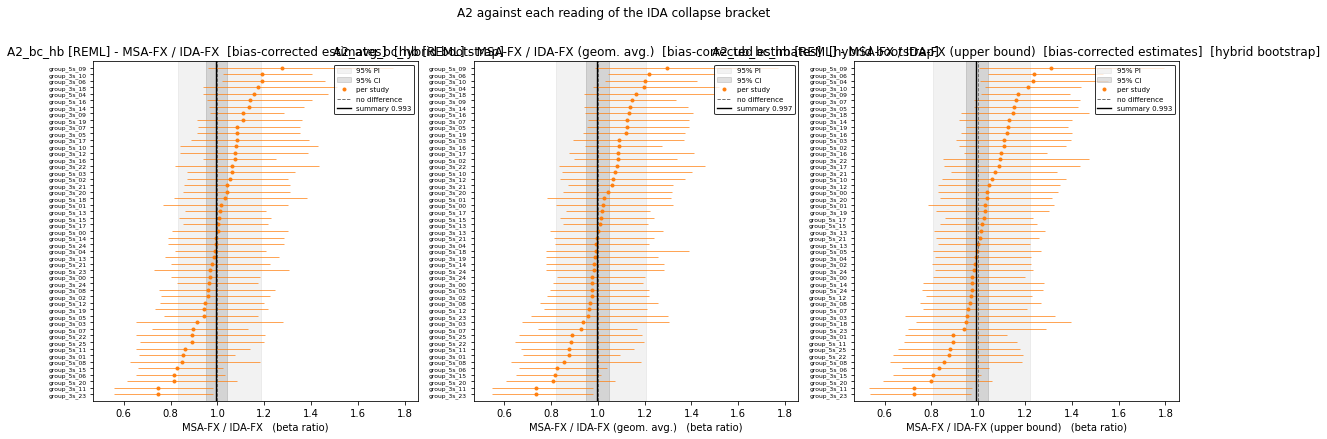

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharex=True)
estimator = "REML"
for ax, model_id in zip(axes, ("A2_bc_hb", "A2_avg_bc_hb", "A2_ub_bc_hb")):
    fits_beta.forest(model_id, estimator=estimator, ax=ax)
fig.suptitle("A2 against each reading of the IDA collapse bracket", y=1.01)
fig.tight_layout()

### 3.4 A3

#### 3.4.1 A3a

##### A3a

In [43]:
print(fits_beta["A3a_bc_hb"].summary()) 

A3a_bc_hb [REML]  [bias-corrected estimates]  [hybrid bootstrap]  MSA-SS / IDA-FX (geom. avg.)  (y0_avg = a - c_avg, beta, n=120)
  summary effect   : 1.0439   (log +0.0430)
  95% CI           : 0.9470 - 1.1610     <- where the MEAN effect lies, for the POPULATION of sites and designs (effects redrawn)
    -> percentile interval of the bias-corrected estimator: replicates shifted by -(2b + s), see FragilityData.replicate_shift
  95% PI           : 0.8559 - 1.2732     <- where the NEXT case lands
  SE (superpop.)   : 0.04932   <- includes tau: a NEW structure
  SE (sampling)    : 0.04603   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.05086   <- 200 refits, hybrid: compare with SE (superpop.)
  tau_d            : 0.0511   (a factor of 1.052)   95% CI 0.0000 - 0.1023, 30% of replicates at 0
  tau_s            : 0.0697   (a factor of 1.072)   95% CI 0.0000 - 0.0988, 18% of replicates at 0
  tau_u            : 0.0000   (a factor of 1.000)   95% CI 0.0000 - 0.0907, 67% of replica

##### A3ac

In [44]:
print(fits_beta["A3ac_bc_hb"].summary())

A3ac_bc_hb [REML]  [bias-corrected estimates]  [hybrid bootstrap]  MSA-SS / IDA-FX (geom. avg.)  (y0_avg = a - c_avg, beta, n=120)
  summary effect   : 1.0346   (log +0.0340)
  95% CI           : 0.9437 - 1.1508     <- where the MEAN effect lies, for the POPULATION of sites and designs (effects redrawn)
    -> percentile interval of the bias-corrected estimator: replicates shifted by -(2b + s), see FragilityData.replicate_shift
  95% PI           : 0.8771 - 1.2205     <- where the NEXT case lands
  SE (superpop.)   : 0.04752   <- includes tau: a NEW structure
  SE (sampling)    : 0.04560   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.04932   <- 200 refits, hybrid: compare with SE (superpop.)
  tau_d            : 0.0303   (a factor of 1.031)   95% CI 0.0000 - 0.0930, 48% of replicates at 0
  tau_s            : 0.0601   (a factor of 1.062)   95% CI 0.0000 - 0.0958, 30% of replicates at 0
  tau_u            : 0.0000   (a factor of 1.000)   95% CI 0.0000 - 0.0858, 75% of replic

##### A3ad

In [45]:
print(fits_beta["A3ad_bc_hb"].summary())

A3ad_bc_hb [REML]  [bias-corrected estimates]  [hybrid bootstrap]  MSA-SS / IDA-FX (geom. avg.)  (y0_avg = a - c_avg, beta, n=120)
  summary effect   : 1.0344   (log +0.0338)
  95% CI           : 0.9403 - 1.1527     <- where the MEAN effect lies, for the POPULATION of sites and designs (effects redrawn)
    -> percentile interval of the bias-corrected estimator: replicates shifted by -(2b + s), see FragilityData.replicate_shift
  95% PI           : 0.8749 - 1.2231     <- where the NEXT case lands
  SE (superpop.)   : 0.04766   <- includes tau: a NEW structure
  SE (sampling)    : 0.04563   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.04962   <- 200 refits, hybrid: compare with SE (superpop.)
  tau_d            : 0.0324   (a factor of 1.033)   95% CI 0.0000 - 0.0940, 50% of replicates at 0
  tau_s            : 0.0604   (a factor of 1.062)   95% CI 0.0000 - 0.0957, 31% of replicates at 0
  tau_u            : 0.0000   (a factor of 1.000)   95% CI 0.0000 - 0.0836, 75% of replic

##### A3ae

In [46]:
print(fits_beta["A3ae_bc_hb"].summary())

A3ae_bc_hb [REML]  [bias-corrected estimates]  [hybrid bootstrap]  MSA-SS / IDA-FX (geom. avg.)  (y0_avg = a - c_avg, beta, n=120)
  summary effect   : 1.0276   (log +0.0272)
  95% CI           : 0.9460 - 1.1442     <- where the MEAN effect lies, for the POPULATION of sites and designs (effects redrawn)
    -> percentile interval of the bias-corrected estimator: replicates shifted by -(2b + s), see FragilityData.replicate_shift
  95% PI           : 0.8203 - 1.2873     <- where the NEXT case lands
  SE (superpop.)   : 0.04808   <- includes tau: a NEW structure
  SE (sampling)    : 0.04505   <- sqrt(w' V w), these structures
  SE (bootstrap)   : 0.05046   <- 200 refits, hybrid: compare with SE (superpop.)
  tau_d            : 0.0163   (a factor of 1.016)   95% CI 0.0000 - 0.0819, 57% of replicates at 0
  tau_s            : 0.1007   (a factor of 1.106)   95% CI 0.0465 - 0.1287, 2% of replicates at 0
  tau_u            : 0.0000   (a factor of 1.000)   95% CI 0.0000 - 0.0910, 73% of replica

### 3.5 Comparisons

In [47]:
cols = ["contrast", "ratio", "se_model", "se_sampling", "se_boot", "tau_d", "tau_s",
        "tau_u", "ci_lo", "ci_hi", "pi_lo", "pi_hi"]
fits_beta.table()[cols].round(4)

,,contrast,ratio,se_model,se_sampling,se_boot,tau_d,tau_s,tau_u,ci_lo,ci_hi,pi_lo,pi_hi
model,estimator,,,,,,,,,,,,
A0b_bc_hb,REML,y0_avg,1.0131,0.0454,0.0437,0.0498,NaN,NaN,0.0828,0.9301,1.1229,0.8367,1.2267
A0c_bc,REML,y0_avg,1.0158,0.0470,0.0441,0.0480,0.0000,0.0992,0.0000,0.9284,1.1131,0.8166,1.2636
A0c_bc_hb,REML,y0_avg,1.0158,0.0470,0.0441,0.0496,0.0000,0.0992,0.0000,0.9258,1.1248,0.8155,1.2654
A2_bc_hb,REML,y2,0.9930,0.0229,0.0151,0.0233,NaN,NaN,0.0856,0.9499,1.0429,0.8309,1.1868
A2_avg_bc_hb,REML,y2_avg,0.9966,0.0243,0.0161,0.0246,NaN,NaN,0.0926,0.9504,1.0469,0.8221,1.2082
A2_ub_bc_hb,REML,y2_ub,0.9928,0.0259,0.0173,0.0261,NaN,NaN,0.1001,0.9463,1.0405,0.8065,1.2222
A3a_bc_hb,REML,y0_avg,1.0439,0.0493,0.0460,0.0509,0.0511,0.0697,0.0000,0.9470,1.1610,0.8559,1.2732
A3ac_bc_hb,REML,y0_avg,1.0346,0.0475,0.0456,0.0493,0.0303,0.0601,0.0000,0.9437,1.1508,0.8771,1.2205
A3ad_bc_hb,REML,y0_avg,1.0344,0.0477,0.0456,0.0496,0.0324,0.0604,0.0000,0.9403,1.1527,0.8749,1.2231


## 4.0 Comparison across models

One call over every fit. Everything is in ratio units: `ratio` is the summary effect as a factor,
`tau_u` the case-to-case SD on the log scale, `ci_*` and `pi_*` the confidence and prediction
intervals.

In [48]:
cols = ["contrast", "n", "ratio", "se_model", "se_sampling", "se_boot",
        "tau_u", "ci_lo", "ci_hi", "pi_lo", "pi_hi"]
fits_theta.table()[cols].round(4)

contrast    n   ratio  se_model  se_sampling  se_boot   tau_u   ci_lo   ci_hi   pi_lo   pi_hi
model  estimator                                                                                              
A0a    DL              y0  120  1.0313    0.0089       0.0257   0.0254  0.0830  0.9831  1.0857  0.8684  1.2248
       REML            y0  120  1.0650    0.0233       0.0203   0.0205  0.0842  1.0225  1.1085  0.8970  1.2645
A1a    DL              y1  120  0.9895    0.0089       0.0276   0.0281  0.0819  0.9444  1.0476  0.8336  1.1746
       REML            y1  120  0.9895    0.0090       0.0276   0.0281  0.0833  0.9445  1.0476  0.8314  1.1777
A1b    REML            y1  120  1.0327    0.0230       0.0188   0.0204  0.0848  0.9888  1.0736  0.8689  1.2273
A1c    REML            y1  120  1.0051    0.0222       0.0167   0.0193  0.0189  0.9669  1.0440  0.8437  1.1975
A2     REML            y2   51  1.0450    0.0024       0.0016   0.0021  0.0097  1.0415  1.0501  1.0243  1.0662
A2_avg REML        y2_avg   51  1.0057    0.0025       0.0017   0.0023  0.0094  1.0024  1.0112  0.9864  1.0254
A2_ub  REML         y2_ub   51  0.9680    0.0028       0.0019   0.0025  0.0098  0.9643  0.9742  0.9485  0.9880
A0b_hb REML        y0_avg  120  1.0265    0.0230       0.0201   0.0227  0.0843  0.9801  1.0714  0.8636  1.2201
A0c    REML        y0_avg  120  1.0068    0.0228       0.0186   0.0203  0.0197  0.9682  1.0480  0.8448  1.1997
A0d    REML            y0  120  1.0441    0.0228       0.0185   0.0203  0.0200  1.0050  1.0866  0.8759  1.2445
A3a    REML        y0_avg  120  0.9942    0.0210       0.0181   0.0199  0.0177  0.9571  1.0353  0.8963  1.1027
A3aa   REML        y0_avg  120  0.9927    0.0206       0.0178   0.0197  0.0187  0.9569  1.0340  0.9008  1.0941
A3ab   REML        y0_avg  120  0.9905    0.0204       0.0177   0.0197  0.0153  0.9556  1.0332  0.8976  1.0930
A3ac   REML        y0_avg  120  0.9967    0.0210       0.0182   0.0196  0.0183  0.9592  1.0391  0.9137  1.0872
A3ad   REML        y0_avg  120  1.0000    0.0199       0.0174   0.0191  0.0172  0.9619  1.0420  0.9260  1.0800
A3ae   REML        y0_avg  120  0.9924    0.0205       0.0178   0.0195  0.0194  0.9577  1.0342  0.9101  1.0822
A3b    REML        y0_avg  120  1.0057    0.0228       0.0186   0.0204  0.0199  0.9678  1.0475  0.8437  1.1988
A3c    REML        y0_avg  120  0.9909    0.0213       0.0183   0.0203  0.0176  0.9537  1.0352  0.8931  1.0995

## 5.0 Statistical Models for Joint $\theta$ and $\beta$

In [49]:
print(fm.check_joint_inputs(theta, beta)["report"])

joint input checks (y0_avg):
  labels / NaN patterns / n_obs : ok for every arm (b, c, c_ub, c_avg, a); k = 5000
  statistical alignment         : ok (k sum r_samp^2 = 15995 on 120 df; ~120 if unaligned)
  V_known 240x240               : min eig 2.42e-04, cond 2.53e+03 (theta block 3.4e+02, beta block 6.9e+01); k/2n = 20.8
  skewness of replicates        : ln beta median +0.15, range -0.94..+0.49; theta median -0.01, range -0.16..+0.13
  r_samp per row                : mean +0.027, median +0.045, range -0.387..+0.439
  r_naive                       : +0.165
  arm b      corr(theta*, beta*) : mean +0.062, range -0.339..+0.419
  arm c      corr(theta*, beta*) : mean +0.037, range -0.560..+0.562
  arm c_ub   corr(theta*, beta*) : mean +0.012, range -0.579..+0.498
  arm c_avg  corr(theta*, beta*) : mean +0.025, range -0.554..+0.533
  arm a      corr(theta*, beta*) : mean +0.074, range -0.468..+0.582


In [50]:
joint = fm.JointModelRegistry(theta, beta)
N_BOOT = 200 # theta.k          # all of them - these are the reportable fits

# Every joint model the sections below read (§5.1 - §5.2).
JOINT_MODELS = ["A8a_bc_hb", "A8b_bc_hb", "A8c_bc_hb"]
for model_id in JOINT_MODELS:
    joint.fit(model_id, n_boot=N_BOOT, verbose=True)

  A8a_bc_hb [REML]: outer bootstrap over 200 replicates (hybrid)...
  A8a_bc_hb: 20/200 replicates
  A8a_bc_hb: 40/200 replicates
  A8a_bc_hb: 60/200 replicates
  A8a_bc_hb: 80/200 replicates
  A8a_bc_hb: 100/200 replicates
  A8a_bc_hb: 120/200 replicates
  A8a_bc_hb: 140/200 replicates
  A8a_bc_hb: 160/200 replicates
  A8a_bc_hb: 180/200 replicates
  A8a_bc_hb: 200/200 replicates
  A8b_bc_hb [REML]: outer bootstrap over 200 replicates (hybrid)...
  A8b_bc_hb: 20/200 replicates
  A8b_bc_hb: 40/200 replicates
  A8b_bc_hb: 60/200 replicates
  A8b_bc_hb: 80/200 replicates
  A8b_bc_hb: 100/200 replicates
  A8b_bc_hb: 120/200 replicates
  A8b_bc_hb: 140/200 replicates
  A8b_bc_hb: 160/200 replicates
  A8b_bc_hb: 180/200 replicates
  A8b_bc_hb: 200/200 replicates
  A8c_bc_hb [REML]: outer bootstrap over 200 replicates (hybrid)...
  A8c_bc_hb: 20/200 replicates
  A8c_bc_hb: 40/200 replicates
  A8c_bc_hb: 60/200 replicates
  A8c_bc_hb: 80/200 replicates
  A8c_bc_hb: 100/200 replicates
  A8c_bc

### 5.1 A8a - joint model with no variance components or covariates

The joint model A8a is equivalent to A0b

In [51]:
print(joint["A8a_bc_hb"].summary())

A8a_bc_hb [REML]  [beta bias-corrected; theta never]  [hybrid bootstrap]  MSA-SS / IDA-FX (geom. avg.)  (y0_avg = a - c_avg, theta+beta, n=120 per outcome)
  theta summary effect : 1.0339   (log +0.0334, SE superpop. 0.01764, SE boot 0.01845)
        95% CI         : 1.0020 - 1.0757   <- for the POPULATION of sites and designs (effects redrawn)
  beta  summary effect : 1.0028   (log +0.0028, SE superpop. 0.04352, SE boot 0.04704)
        95% CI         : 0.9145 - 1.1169   <- for the POPULATION of sites and designs (effects redrawn)
  corr(m_theta, m_beta) : +0.091   [bootstrap]
  between-row covariance, per level (tau as SD; rho = true-correction corr.):
    row     tau_theta 0.0877 [100.0%]  tau_beta 0.0917 [100.0%]  rho -0.068   boot: 0% at bound, 0% undefined
  rho_tot          : -0.068   95% CI -0.481 .. +0.555 (percentile), -0.831 .. +0.783 (Fisher z)
    -> hybrid replicates: mean T_total tt 0.00770, bb 0.00842, tb -0.00045   against the fitted 0.00769, 0.00840, -0.00055 (they sh

TODO:: The results here are interesting because the SE of theta is significantly reduced

### 5.2 Joint Model with variance components and no covariates

#### 5.2.1 A8b --> correlation of rows only

This joint model has the same covariance structure as A0c but only considers one correlation

In [52]:
print(joint["A8b_bc_hb"].summary())

A8b_bc_hb [REML]  [beta bias-corrected; theta never]  [hybrid bootstrap]  MSA-SS / IDA-FX (geom. avg.)  (y0_avg = a - c_avg, theta+beta, n=120 per outcome)
  theta summary effect : 1.0166   (log +0.0164, SE superpop. 0.01833, SE boot 0.01976)
        95% CI         : 0.9809 - 1.0562   <- for the POPULATION of sites and designs (effects redrawn)
  beta  summary effect : 1.0103   (log +0.0103, SE superpop. 0.04387, SE boot 0.04697)
        95% CI         : 0.9332 - 1.1057   <- for the POPULATION of sites and designs (effects redrawn)
  corr(m_theta, m_beta) : +0.162   [bootstrap]
  between-row covariance, per level (tau as SD; rho = true-correction corr.):
    design  tau_theta 0.0000 (0) [ 0.0%]  tau_beta 0.0236 [ 4.7%]  rho fixed at 0
    site    tau_theta 0.0861 [93.3%]  tau_beta 0.1065 [94.9%]  rho fixed at 0
    row     tau_theta 0.0230 [ 6.7%]  tau_beta 0.0068 [ 0.4%]  rho -1.000  <- ON THE |rho| = 1 BOUNDARY   boot: 72% at bound, 0% undefined
  rho_tot          : -0.016   95% CI -

#### 5.2.2 A8c --> correlation of all components

The joint model A8c is equivalent to A0c and considers the correlation between all of the variance components

In [53]:
print(joint["A8c_bc_hb"].summary())

A8c_bc_hb [REML]  [beta bias-corrected; theta never]  [hybrid bootstrap]  MSA-SS / IDA-FX (geom. avg.)  (y0_avg = a - c_avg, theta+beta, n=120 per outcome)
  theta summary effect : 1.0139   (log +0.0138, SE superpop. 0.01869, SE boot 0.01931)
        95% CI         : 0.9793 - 1.0548   <- for the POPULATION of sites and designs (effects redrawn)
  beta  summary effect : 1.0045   (log +0.0045, SE superpop. 0.04445, SE boot 0.04814)
        95% CI         : 0.9229 - 1.1077   <- for the POPULATION of sites and designs (effects redrawn)
  corr(m_theta, m_beta) : +0.140   [bootstrap]
  between-row covariance, per level (tau as SD; rho = true-correction corr.):
    design  tau_theta 0.0081 [ 0.8%]  tau_beta 0.0360 [10.5%]  rho +1.000  <- ON THE |rho| = 1 BOUNDARY   boot: 76% at bound, 15% undefined
    site    tau_theta 0.0857 [93.0%]  tau_beta 0.1045 [88.7%]  rho -0.021   boot: 0% at bound, 0% undefined
    row     tau_theta 0.0220 [ 6.2%]  tau_beta 0.0098 [ 0.8%]  rho -1.000  <- ON THE |rho